# Post-Experiment Analysis

Standard notebook for vulnerability classification runs with emphasis on CWE generalization, conservatism vs over-prediction, weak buckets, threshold sensitivity, and repeatable comparisons.

Interpretation rules encoded here:
- Accuracy can mislead because vulnerability data is usually imbalanced.
- `unseen_test` is the key split for CWE generalization.
- High unseen precision with lower unseen recall usually means the model is conservative on unseen CWE.
- Per-CWE metrics matter because aggregate metrics can hide failures in rare classes.
- Threshold analysis matters because recall/F1 may improve without retraining.

In [1]:
import os
os.chdir("/Users/noamc/repos/graph-vul")

In [2]:
from pathlib import Path

# Minimal config edits for each future run.
RUN_NAME = "func_finetune_model_ckpt"
MODEL_NAME = "microsoft/unixcoder-base + CWE embedding fusion (fine-tuned)"
DATASET_NAME = "data/func_subset.csv with data/func_splits/assignments.csv"
UNSEEN_DEFINITION = "Held-out CWE categories (CWE-200, CWE-416) excluded from train/val/test and evaluated in unseen splits."
CAVEATS = [
    "Per-row prediction files are required for full analysis.",
    "If only hard labels exist, score and threshold sections will be skipped.",
]

PREDICTION_PATHS = {
    "val": "data/analysis/func_finetune_predictions/val_predictions.csv",
    "test": "data/analysis/func_finetune_predictions/test_predictions.csv",
    "unseen_test": "data/analysis/func_finetune_predictions/unseen_test_predictions.csv",
    # Optional if your run produces these:
    "unseen_val": "data/analysis/func_finetune_predictions/unseen_val_predictions.csv",
    "train": None,
}

OPTIONAL_METRICS_PATHS = {
    "metrics_json": None,
}

THRESHOLD = 0.50
SCORE_KIND_OVERRIDE = "auto"  # "auto", "prob", or "logit"
THRESHOLD_GRID = [round(x, 2) for x in __import__("numpy").linspace(0.05, 0.95, 19)]
N_BOOTSTRAP = 1000

OUTPUT_DIR = Path("outputs") / "post_experiment_analysis" / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Run: {RUN_NAME}")
print(f"Output dir: {OUTPUT_DIR.resolve()}")

Run: func_finetune_model_ckpt
Output dir: /Users/noamc/repos/graph-vul/outputs/post_experiment_analysis/func_finetune_model_ckpt


## Overview

**Model**: `{{ MODEL_NAME }}`  
**Dataset / subset**: `{{ DATASET_NAME }}`  
**What counts as unseen**: `{{ UNSEEN_DEFINITION }}`

Update the config cell above with the actual values for this run. This notebook assumes per-row prediction files by split and will skip sections that are not supported by the available columns.

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from graph_vul.analysis import post_experiment_analysis as pea

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
plt.style.use("default")
np.random.seed(pea.RANDOM_SEED)

## Load Predictions

This section validates the input files before any metric interpretation. It checks shapes, columns, class balance, unique CWE/project counts, duplicate IDs when available, null predictions, and malformed probability values.

If the current run output schema is missing fields such as `cwe_id`, `project`, `is_unseen_cwe`, scores, or metadata lengths, the notebook will emit a TODO-style warning and skip only the affected analyses.

In [4]:
frames, load_metadata = pea.load_prediction_splits(
    PREDICTION_PATHS,
    threshold=THRESHOLD,
    score_kind_override=SCORE_KIND_OVERRIDE,
)
frames = pea.derive_unseen_flags(frames)

if not frames:
    raise FileNotFoundError("No prediction files were loaded. Update PREDICTION_PATHS in the config cell.")

display(Markdown("### Run Metadata"))
display(pd.DataFrame({
    "field": ["run_name", "model_name", "dataset_name", "unseen_definition", "threshold"],
    "value": [RUN_NAME, MODEL_NAME, DATASET_NAME, UNSEEN_DEFINITION, THRESHOLD],
}))
if CAVEATS:
    display(Markdown("### Caveats"))
    for caveat in CAVEATS:
        display(Markdown(f"- {caveat}"))

split_summaries = []
for split_name, frame in frames.items():
    split_summary = pea.summarize_split_frame(frame)
    split_summary.name = split_name
    split_summaries.append(split_summary)
display(Markdown("### Split Summary"))
display(pd.DataFrame(split_summaries))

for split_name, frame in frames.items():
    display(Markdown(f"### `{split_name}` column summary"))
    display(pd.DataFrame({"column": frame.columns, "dtype": [str(frame[c].dtype) for c in frame.columns]}))
    display(Markdown(f"**Label balance for `{split_name}`**"))
    label_balance = frame["y_true"].value_counts(dropna=False).rename_axis("label").reset_index(name="count")
    label_balance["share"] = label_balance["count"] / label_balance["count"].sum()
    display(label_balance)
    display(Markdown(f"**Validation checks for `{split_name}`**"))
    display(pea.validation_checks(frame))

design_checks = pea.confirm_unseen_split_design(frames)
if not design_checks.empty:
    display(Markdown("### Seen vs unseen split design checks"))
    display(design_checks)
else:
    print("TODO: Could not confirm seen/unseen split design because `is_unseen_cwe` or `cwe_id` is missing.")

### Run Metadata

,field,value
0,run_name,func_finetune_model_ckpt
1,model_name,microsoft/unixcoder-base + CWE embedding fusio...
2,dataset_name,data/func_subset.csv with data/func_splits/ass...
3,unseen_definition,"Held-out CWE categories (CWE-200, CWE-416) exc..."
4,threshold,0.5


### Caveats

- Per-row prediction files are required for full analysis.

- If only hard labels exist, score and threshold sections will be skipped.

...

,label,count,share
0,0,14232,0.935946
1,1,974,0.064054


**Validation checks for `unseen_val`**

,check,value
0,missing_y_true,0
1,missing_y_pred,0
2,missing_score,0
3,malformed_probability_values,0
4,duplicate_row_id,0
5,missing_cwe_id,0
6,missing_project,0


### Seen vs unseen split design checks

,check,value
0,unseen_test_all_heldout,True
1,test_contains_only_seen_cwe,True
2,test_unseen_share,0.0


## Aggregate Metrics

Accuracy is included for completeness, but it is not the main metric. For imbalanced vulnerability detection, precision, recall, and F1 are more informative. The key comparison is `test` vs `unseen_test`.

In [5]:
aggregate_metrics = pea.aggregate_metrics_table(frames)
aggregate_metrics = aggregate_metrics[[
    "support", "positive_rate", "accuracy", "precision", "recall", "f1",
    "TP", "FP", "TN", "FN", "roc_auc", "pr_auc", "brier_score",
]]
display(aggregate_metrics.round(4))
pea.save_dataframe(aggregate_metrics.reset_index(), OUTPUT_DIR / "aggregate_metrics.csv")

interpretation = pea.interpretation_for_test_vs_unseen(aggregate_metrics)
display(Markdown("### Automatic Interpretation"))
display(Markdown(interpretation))

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,roc_auc,pr_auc,brier_score
split,,,,,,,,,,,,,
test,4727,0.0235,0.9945,0.9208,0.8378,0.8774,93,8,4608,18,NaN,NaN,NaN
unseen_test,14711,0.0599,0.9861,0.9555,0.8048,0.8737,709,33,13797,172,NaN,NaN,NaN
unseen_val,15206,0.0641,0.9075,0.3931,0.8172,0.5308,796,1229,13003,178,NaN,NaN,NaN
val,8465,0.0465,0.9892,0.9577,0.8046,0.8745,317,14,8057,77,NaN,NaN,NaN


### Automatic Interpretation

Unseen F1 change vs test is -0.004 (small gap). Unseen precision change is +0.035; unseen recall change is -0.033. The unseen pattern looks conservative: recall drops more than precision.

## Seen vs Unseen

This section asks whether the gap is mostly in recall, whether the model is more conservative on unseen CWE, and whether false positives or false negatives dominate.

,group,support,positive_rate,precision,recall,f1,fp_rate,fn_rate,TP,FP,TN,FN
1,unseen_cwe,14711,0.0599,0.9555,0.8048,0.8737,0.0024,0.1952,709,33,13797,172
0,seen_cwe,4727,0.0235,0.9208,0.8378,0.8774,0.0017,0.1622,93,8,4608,18


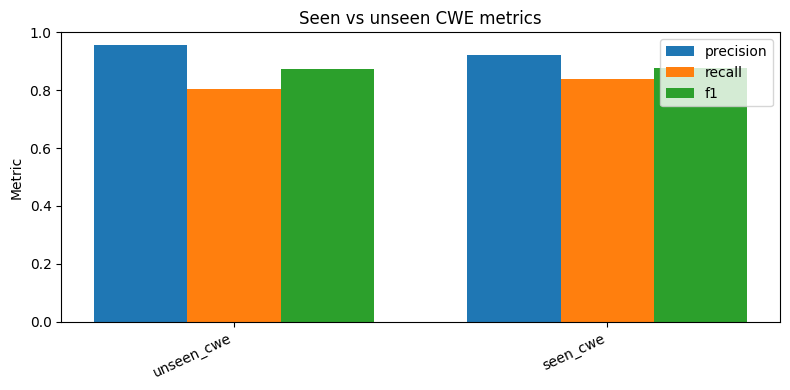

In [6]:
primary_eval_splits = [split for split in ["test", "unseen_test"] if split in frames]
if not primary_eval_splits:
    primary_eval_splits = [split for split in frames if split != "train"]
eval_df = pd.concat([frames[split].assign(eval_split=split) for split in primary_eval_splits], ignore_index=True)

seen_unseen_metrics = pd.DataFrame()
if "is_unseen_cwe" in eval_df.columns:
    seen_unseen_metrics = pea.grouped_metrics(eval_df, "is_unseen_cwe")
    seen_unseen_metrics["group"] = seen_unseen_metrics["is_unseen_cwe"].map({0: "seen_cwe", 1: "unseen_cwe"}).fillna("unknown")
    seen_unseen_metrics = seen_unseen_metrics[[
        "group", "support", "positive_rate", "precision", "recall", "f1", "fp_rate", "fn_rate", "TP", "FP", "TN", "FN"
    ]]
    display(seen_unseen_metrics.round(4))
    pea.save_dataframe(seen_unseen_metrics, OUTPUT_DIR / "seen_unseen_metrics.csv")

    fig = pea.plot_metric_bars(seen_unseen_metrics, "group", ["precision", "recall", "f1"], "Seen vs unseen CWE metrics")
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "seen_vs_unseen_metrics.png")
    plt.close(fig)
else:
    print("TODO: `is_unseen_cwe` not available or not derivable; skipping grouped seen/unseen analysis.")

## Per-CWE Analysis

Aggregate metrics can hide instability in rare classes. This section is one of the main decision points for future runs.

### Worst CWEs by F1

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,cwe_id,vulnerable_examples,benign_examples,is_unseen_cwe
11,64,0.0000,1.0000,0.0,0.0000,0.0000,0,0,64,0,0.0000,NaN,NaN,NaN,NaN,CWE-254,0,64,1
17,51,0.0000,0.9804,0.0,0.0000,0.0000,0,1,50,0,0.0196,NaN,NaN,NaN,NaN,CWE-290,0,51,1
44,42,0.0000,1.0000,0.0,0.0000,0.0000,0,0,42,0,0.0000,NaN,NaN,NaN,NaN,CWE-79,0,42,1
26,20,0.0000,1.0000,0.0,0.0000,0.0000,0,0,20,0,0.0000,NaN,NaN,NaN,NaN,CWE-388,0,20,1
15,16,0.0625,0.9375,0.0,0.0000,0.0000,0,0,15,1,0.0000,1.0000,NaN,NaN,NaN,CWE-284,1,15,1
33,16,0.0000,1.0000,0.0,0.0000,0.0000,0,0,16,0,0.0000,NaN,NaN,NaN,NaN,CWE-502,0,16,1
49,15,0.0000,1.0000,0.0,0.0000,0.0000,0,0,15,0,0.0000,NaN,NaN,NaN,NaN,CWE-90,0,15,1
12,13,0.0769,0.9231,0.0,0.0000,0.0000,0,0,12,1,0.0000,1.0000,NaN,NaN,NaN,CWE-255,1,12,1
4,10,0.1000,0.9000,0.0,0.0000,0.0000,0,0,9,1,0.0000,1.0000,NaN,NaN,NaN,CWE-17,1,9,1
21,2,0.0000,1.0000,0.0,0.0000,0.0000,0,0,2,0,0.0000,NaN,NaN,NaN,NaN,CWE-327,0,2,1


### Worst CWEs by recall

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,cwe_id,vulnerable_examples,benign_examples,is_unseen_cwe
11,64,0.0000,1.0000,0.0,0.0000,0.0000,0,0,64,0,0.0000,NaN,NaN,NaN,NaN,CWE-254,0,64,1
17,51,0.0000,0.9804,0.0,0.0000,0.0000,0,1,50,0,0.0196,NaN,NaN,NaN,NaN,CWE-290,0,51,1
44,42,0.0000,1.0000,0.0,0.0000,0.0000,0,0,42,0,0.0000,NaN,NaN,NaN,NaN,CWE-79,0,42,1
26,20,0.0000,1.0000,0.0,0.0000,0.0000,0,0,20,0,0.0000,NaN,NaN,NaN,NaN,CWE-388,0,20,1
15,16,0.0625,0.9375,0.0,0.0000,0.0000,0,0,15,1,0.0000,1.0000,NaN,NaN,NaN,CWE-284,1,15,1
33,16,0.0000,1.0000,0.0,0.0000,0.0000,0,0,16,0,0.0000,NaN,NaN,NaN,NaN,CWE-502,0,16,1
49,15,0.0000,1.0000,0.0,0.0000,0.0000,0,0,15,0,0.0000,NaN,NaN,NaN,NaN,CWE-90,0,15,1
12,13,0.0769,0.9231,0.0,0.0000,0.0000,0,0,12,1,0.0000,1.0000,NaN,NaN,NaN,CWE-255,1,12,1
4,10,0.1000,0.9000,0.0,0.0000,0.0000,0,0,9,1,0.0000,1.0000,NaN,NaN,NaN,CWE-17,1,9,1
21,2,0.0000,1.0000,0.0,0.0000,0.0000,0,0,2,0,0.0000,NaN,NaN,NaN,NaN,CWE-327,0,2,1


### Best CWEs

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,cwe_id,vulnerable_examples,benign_examples,is_unseen_cwe
42,193,0.0311,1.0000,1.000,1.0000,1.0000,6,0,187,0,0.0000,0.0000,NaN,NaN,NaN,CWE-78,6,187,1
10,77,0.0130,1.0000,1.000,1.0000,1.0000,1,0,76,0,0.0000,0.0000,NaN,NaN,NaN,CWE-22,1,76,1
34,74,0.0135,1.0000,1.000,1.0000,1.0000,1,0,73,0,0.0000,0.0000,NaN,NaN,NaN,CWE-532,1,73,1
16,69,0.0435,1.0000,1.000,1.0000,1.0000,3,0,66,0,0.0000,0.0000,NaN,NaN,NaN,CWE-287,3,66,1
3,44,0.0227,1.0000,1.000,1.0000,1.0000,1,0,43,0,0.0000,0.0000,NaN,NaN,NaN,CWE-134,1,43,1
20,40,0.1000,1.0000,1.000,1.0000,1.0000,4,0,36,0,0.0000,0.0000,NaN,NaN,NaN,CWE-320,4,36,1
48,24,0.1250,1.0000,1.000,1.0000,1.0000,3,0,21,0,0.0000,0.0000,NaN,NaN,NaN,CWE-89,3,21,1
50,18,0.0556,1.0000,1.000,1.0000,1.0000,1,0,17,0,0.0000,0.0000,NaN,NaN,NaN,CWE-918,1,17,1
40,10,0.2000,1.0000,1.000,1.0000,1.0000,2,0,8,0,0.0000,0.0000,NaN,NaN,NaN,CWE-74,2,8,1
37,7,0.1429,1.0000,1.000,1.0000,1.0000,1,0,6,0,0.0000,0.0000,NaN,NaN,NaN,CWE-665,1,6,1


### Seen CWE table

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,cwe_id,vulnerable_examples,benign_examples,is_unseen_cwe
6,1103,0.0363,0.9909,0.9167,0.825,0.8684,33,3,1060,7,0.0028,0.175,NaN,NaN,NaN,CWE-189,40,1063,0
14,726,0.0165,0.9972,0.8571,1.000,0.9231,12,2,712,0,0.0028,0.000,NaN,NaN,NaN,CWE-269,12,714,0
36,806,0.0099,0.9988,1.0000,0.875,0.9333,7,0,798,1,0.0000,0.125,NaN,NaN,NaN,CWE-617,8,798,0


### Unseen CWE table

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,cwe_id,vulnerable_examples,benign_examples,is_unseen_cwe
11,64,0.0000,1.0000,0.0,0.0000,0.0000,0,0,64,0,0.0000,NaN,NaN,NaN,NaN,CWE-254,0,64,1
17,51,0.0000,0.9804,0.0,0.0000,0.0000,0,1,50,0,0.0196,NaN,NaN,NaN,NaN,CWE-290,0,51,1
44,42,0.0000,1.0000,0.0,0.0000,0.0000,0,0,42,0,0.0000,NaN,NaN,NaN,NaN,CWE-79,0,42,1
26,20,0.0000,1.0000,0.0,0.0000,0.0000,0,0,20,0,0.0000,NaN,NaN,NaN,NaN,CWE-388,0,20,1
15,16,0.0625,0.9375,0.0,0.0000,0.0000,0,0,15,1,0.0000,1.0000,NaN,NaN,NaN,CWE-284,1,15,1
33,16,0.0000,1.0000,0.0,0.0000,0.0000,0,0,16,0,0.0000,NaN,NaN,NaN,NaN,CWE-502,0,16,1
49,15,0.0000,1.0000,0.0,0.0000,0.0000,0,0,15,0,0.0000,NaN,NaN,NaN,NaN,CWE-90,0,15,1
12,13,0.0769,0.9231,0.0,0.0000,0.0000,0,0,12,1,0.0000,1.0000,NaN,NaN,NaN,CWE-255,1,12,1
4,10,0.1000,0.9000,0.0,0.0000,0.0000,0,0,9,1,0.0000,1.0000,NaN,NaN,NaN,CWE-17,1,9,1
21,2,0.0000,1.0000,0.0,0.0000,0.0000,0,0,2,0,0.0000,NaN,NaN,NaN,NaN,CWE-327,0,2,1


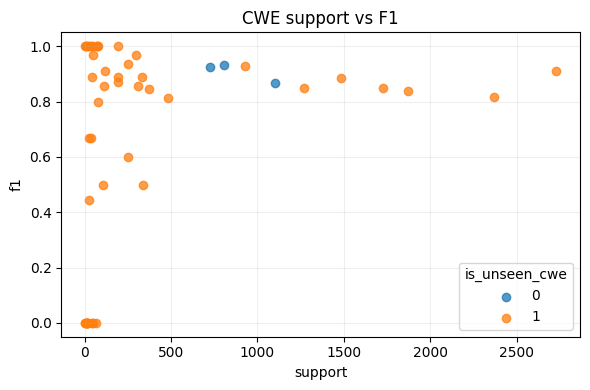

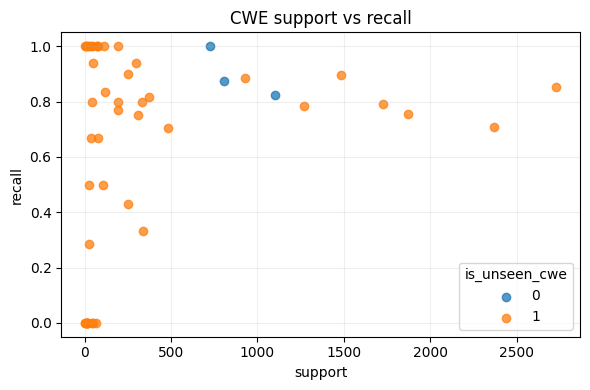

**Caution:** 4 CWE rows have support < 10, so their per-class metrics may be unstable.

In [7]:
per_cwe = pea.per_cwe_metrics(eval_df)
if per_cwe.empty:
    print("TODO: `cwe_id` is missing; skipping per-CWE analysis.")
else:
    pea.save_dataframe(per_cwe, OUTPUT_DIR / "per_cwe_metrics.csv")
    display(Markdown("### Worst CWEs by F1"))
    display(per_cwe.sort_values(["f1", "support"], ascending=[True, False]).head(15).round(4))
    display(Markdown("### Worst CWEs by recall"))
    display(per_cwe.sort_values(["recall", "support"], ascending=[True, False]).head(15).round(4))
    display(Markdown("### Best CWEs"))
    display(per_cwe.sort_values(["f1", "support"], ascending=[False, False]).head(15).round(4))
    if "is_unseen_cwe" in per_cwe.columns:
        display(Markdown("### Seen CWE table"))
        display(per_cwe[per_cwe["is_unseen_cwe"] == 0].sort_values(["f1", "support"], ascending=[True, False]).head(15).round(4))
        display(Markdown("### Unseen CWE table"))
        display(per_cwe[per_cwe["is_unseen_cwe"] == 1].sort_values(["f1", "support"], ascending=[True, False]).head(15).round(4))

    fig = pea.plot_support_scatter(per_cwe, "support", "f1", "CWE support vs F1", hue_col="is_unseen_cwe" if "is_unseen_cwe" in per_cwe.columns else None)
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "per_cwe_support_vs_f1.png")
    plt.close(fig)

    fig = pea.plot_support_scatter(per_cwe, "support", "recall", "CWE support vs recall", hue_col="is_unseen_cwe" if "is_unseen_cwe" in per_cwe.columns else None)
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "per_cwe_support_vs_recall.png")
    plt.close(fig)

    low_support = per_cwe[per_cwe["support"] < 10]
    if not low_support.empty:
        display(Markdown(f"**Caution:** {len(low_support)} CWE rows have support < 10, so their per-class metrics may be unstable."))

## Per-Project Analysis

This section checks whether errors are concentrated in a few repositories or whether the model underperforms consistently across projects.

### Largest projects

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,project,vulnerable_examples,benign_examples,unique_cwes
8,1737,0.0345,0.9937,0.9455,0.8667,0.9043,52,3,1674,8,0.0018,0.1333,NaN,NaN,NaN,ghostscript,60,1677,11
0,1695,0.0490,0.9858,0.9538,0.7470,0.8378,62,3,1609,21,0.0019,0.2530,NaN,NaN,NaN,FFmpeg,83,1612,15
36,1456,0.1422,0.9732,0.9719,0.8357,0.8987,173,5,1244,34,0.0040,0.1643,NaN,NaN,NaN,php-src,207,1249,17
32,1419,0.0648,0.9767,0.9275,0.6957,0.7950,64,5,1322,28,0.0038,0.3043,NaN,NaN,NaN,openssl,92,1327,19
10,1204,0.0108,0.9975,0.9167,0.8462,0.8800,11,1,1190,2,0.0008,0.1538,NaN,NaN,NaN,gpac,13,1191,4
39,1101,0.0509,0.9873,0.9200,0.8214,0.8679,46,4,1041,10,0.0038,0.1786,NaN,NaN,NaN,radare2,56,1045,6
47,1087,0.0276,0.9982,0.9667,0.9667,0.9667,29,1,1056,1,0.0009,0.0333,NaN,NaN,NaN,xserver,30,1057,9
38,968,0.0341,0.9886,0.8929,0.7576,0.8197,25,3,932,8,0.0032,0.2424,NaN,NaN,NaN,poppler,33,935,6
20,668,0.0299,0.9955,0.9474,0.9000,0.9231,18,1,647,2,0.0015,0.1000,NaN,NaN,NaN,libarchive,20,648,11
3,660,0.0167,0.9970,0.8462,1.0000,0.9167,11,2,647,0,0.0031,0.0000,NaN,NaN,NaN,OpenJK,11,649,1


### Worst projects by F1

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,project,vulnerable_examples,benign_examples,unique_cwes
25,30,0.0000,1.0000,0.0000,0.0000,0.0000,0,0,30,0,0.0000,NaN,NaN,NaN,NaN,lynx-snapshots,0,30,1
49,12,0.0833,0.9167,0.0000,0.0000,0.0000,0,0,11,1,0.0000,1.0000,NaN,NaN,NaN,yubico-pam,1,11,1
27,7,0.0000,1.0000,0.0000,0.0000,0.0000,0,0,7,0,0.0000,NaN,NaN,NaN,NaN,mongoose-os,0,7,1
46,102,0.0098,0.9706,0.2500,1.0000,0.4000,1,3,98,0,0.0297,0.0000,NaN,NaN,NaN,wolfssl,1,101,1
45,272,0.0074,0.9963,1.0000,0.5000,0.6667,1,0,270,1,0.0000,0.5000,NaN,NaN,NaN,udisks,2,270,1
11,89,0.0449,0.9775,1.0000,0.5000,0.6667,2,0,85,2,0.0000,0.5000,NaN,NaN,NaN,gstreamer,4,85,4
50,40,0.0500,0.9750,1.0000,0.5000,0.6667,1,0,38,1,0.0000,0.5000,NaN,NaN,NaN,zfs,2,38,1
44,142,0.1268,0.9437,0.9167,0.6111,0.7333,11,1,123,7,0.0081,0.3889,NaN,NaN,NaN,u-boot,18,124,1
1,337,0.0475,0.9792,0.9091,0.6250,0.7407,10,1,320,6,0.0031,0.3750,NaN,NaN,NaN,ImageMagick6,16,321,6
31,198,0.1364,0.9444,1.0000,0.5926,0.7442,16,0,171,11,0.0000,0.4074,NaN,NaN,NaN,openjpeg,27,171,8


### Highest FN count projects

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,project,vulnerable_examples,benign_examples,unique_cwes
36,1456,0.1422,0.9732,0.9719,0.8357,0.8987,173,5,1244,34,0.0040,0.1643,NaN,NaN,NaN,php-src,207,1249,17
32,1419,0.0648,0.9767,0.9275,0.6957,0.7950,64,5,1322,28,0.0038,0.3043,NaN,NaN,NaN,openssl,92,1327,19
0,1695,0.0490,0.9858,0.9538,0.7470,0.8378,62,3,1609,21,0.0019,0.2530,NaN,NaN,NaN,FFmpeg,83,1612,15
17,493,0.2008,0.9757,1.0000,0.8788,0.9355,87,0,394,12,0.0000,0.1212,NaN,NaN,NaN,krb5,99,394,13
31,198,0.1364,0.9444,1.0000,0.5926,0.7442,16,0,171,11,0.0000,0.4074,NaN,NaN,NaN,openjpeg,27,171,8
39,1101,0.0509,0.9873,0.9200,0.8214,0.8679,46,4,1041,10,0.0038,0.1786,NaN,NaN,NaN,radare2,56,1045,6
41,440,0.0818,0.9795,1.0000,0.7500,0.8571,27,0,404,9,0.0000,0.2500,NaN,NaN,NaN,samba,36,404,10
42,316,0.0759,0.9684,0.9375,0.6250,0.7500,15,1,291,9,0.0034,0.3750,NaN,NaN,NaN,src,24,292,7
8,1737,0.0345,0.9937,0.9455,0.8667,0.9043,52,3,1674,8,0.0018,0.1333,NaN,NaN,NaN,ghostscript,60,1677,11
38,968,0.0341,0.9886,0.8929,0.7576,0.8197,25,3,932,8,0.0032,0.2424,NaN,NaN,NaN,poppler,33,935,6


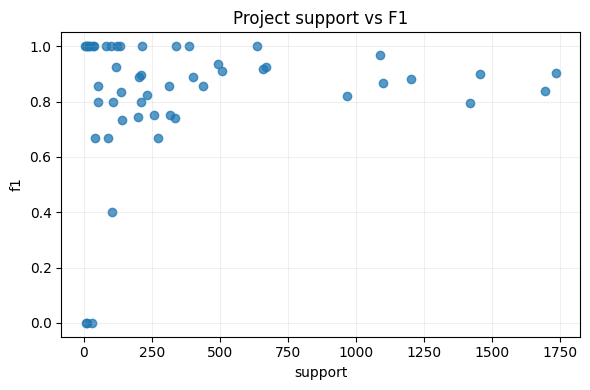

### Project x seen/unseen counts

is_unseen_cwe,0,1
project,,
FFmpeg,0,1695
ImageMagick6,0,337
NetworkManager,0,36
OpenJK,660,0
abrt,0,53
acpica,0,15
curl,0,215
exempi,0,233
ghostscript,0,1737


### Project x CWE count

,project,unique_cwes
0,openssl,19
1,php-src,17
2,FFmpeg,15
3,krb5,13
4,libarchive,11
5,ghostscript,11
6,samba,10
7,xserver,9
8,openjpeg,8
9,src,7


In [8]:
per_project = pea.per_project_metrics(eval_df)
if per_project.empty:
    print("TODO: `project` is missing; skipping per-project analysis.")
else:
    pea.save_dataframe(per_project, OUTPUT_DIR / "per_project_metrics.csv")
    display(Markdown("### Largest projects"))
    display(per_project.sort_values("support", ascending=False).head(15).round(4))
    display(Markdown("### Worst projects by F1"))
    display(per_project.sort_values(["f1", "support"], ascending=[True, False]).head(15).round(4))
    display(Markdown("### Highest FN count projects"))
    display(per_project.sort_values(["FN", "support"], ascending=[False, False]).head(15).round(4))

    fig = pea.plot_support_scatter(per_project, "support", "f1", "Project support vs F1")
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "per_project_support_vs_f1.png")
    plt.close(fig)

    if "is_unseen_cwe" in eval_df.columns:
        project_seen_crosstab = eval_df.pivot_table(index="project", columns="is_unseen_cwe", values="y_true", aggfunc="size", fill_value=0)
        display(Markdown("### Project x seen/unseen counts"))
        display(project_seen_crosstab.head(25))
    if "cwe_id" in eval_df.columns:
        project_cwe_counts = eval_df.groupby("project")["cwe_id"].nunique().sort_values(ascending=False).rename("unique_cwes").reset_index()
        display(Markdown("### Project x CWE count"))
        display(project_cwe_counts.head(25))

## Error Analysis

False negatives matter because missed vulnerabilities are operationally costly. False positives matter because they create review burden. Both are broken down by CWE, project, length bucket, and score bucket when possible.

In [9]:
length_edges = pea.DEFAULT_LENGTH_BUCKETS["token_length"]
fn_df = pea.error_frame(eval_df, "fn")
fp_df = pea.error_frame(eval_df, "fp")
fn_df = pea.bucket_scores(pea.add_length_buckets(fn_df, "token_length", length_edges))
fp_df = pea.bucket_scores(pea.add_length_buckets(fp_df, "token_length", length_edges))

display(Markdown(f"### False negatives: {len(fn_df)} rows"))
display(Markdown(f"Rate within evaluation set: {len(fn_df) / len(eval_df):.3f}"))
display(Markdown(f"### False positives: {len(fp_df)} rows"))
display(Markdown(f"Rate within evaluation set: {len(fp_df) / len(eval_df):.3f}"))

if "cwe_id" in eval_df.columns:
    display(Markdown("### CWE with highest FN count"))
    display(fn_df.groupby("cwe_id").size().sort_values(ascending=False).head(15).rename("fn_count").reset_index())
    display(Markdown("### CWE with highest FP count"))
    display(fp_df.groupby("cwe_id").size().sort_values(ascending=False).head(15).rename("fp_count").reset_index())
if "project" in eval_df.columns:
    display(Markdown("### Project with highest FN count"))
    display(fn_df.groupby("project").size().sort_values(ascending=False).head(15).rename("fn_count").reset_index())
    display(Markdown("### Project with highest FP count"))
    display(fp_df.groupby("project").size().sort_values(ascending=False).head(15).rename("fp_count").reset_index())
if "token_length_bucket" in fn_df.columns:
    display(Markdown("### FN by token-length bucket"))
    display(fn_df.groupby("token_length_bucket", observed=False).size().rename("fn_count").reset_index())
    display(Markdown("### FP by token-length bucket"))
    display(fp_df.groupby("token_length_bucket", observed=False).size().rename("fp_count").reset_index())
if "score_bucket" in fn_df.columns:
    display(Markdown("### FN by score bucket"))
    display(fn_df.groupby("score_bucket", observed=False).size().rename("fn_count").reset_index())
    display(Markdown("### FP by score bucket"))
    display(fp_df.groupby("score_bucket", observed=False).size().rename("fp_count").reset_index())

display(Markdown("### Sample false negatives"))
display(pea.sample_error_rows(fn_df, n=20))
display(Markdown("### Sample false positives"))
display(pea.sample_error_rows(fp_df, n=20))

### False negatives: 190 rows

Rate within evaluation set: 0.010

### False positives: 41 rows

Rate within evaluation set: 0.002

### CWE with highest FN count

...

,score_bucket,fp_count
0,0.0-0.1,0
1,0.1-0.2,0
2,0.2-0.3,0
3,0.3-0.4,0
4,0.4-0.5,0
5,0.5-0.6,7
6,0.6-0.7,3
7,0.7-0.8,2
8,0.8-0.9,6
9,0.9-1.0,23


### Sample false negatives

,row_id,project,cwe_id,y_true,y_pred,score,token_length,code_preview
4617,73054,poppler,CWE-189,1,0,6.898475e-04,512,void SplashOutputDev::drawImage(GfxState *stat...
4623,73060,poppler,CWE-189,1,0,2.271149e-01,512,"GfxImageColorMap::GfxImageColorMap(int bitsA, ..."
4630,73067,poppler,CWE-189,1,0,2.350253e-06,512,void SplashOutputDev::drawMaskedImage(GfxState...
4631,73068,poppler,CWE-189,1,0,1.035483e-06,512,void SplashOutputDev::drawSoftMaskedImage(GfxS...
4634,73071,poppler,CWE-189,1,0,1.443263e-07,512,"GBool SplashFTFont::makeGlyph(int c, int xFrac..."
4645,73263,poppler,CWE-20,1,0,3.744967e-05,512,"void FoFiType1::parse() { char *line, *line1, ..."
4654,73526,xserver,CWE-59,1,0,9.201176e-03,512,"LockServer(void) { char tmp[PATH_MAX], pid_str..."
4660,73576,poppler,CWE-119,1,0,9.355792e-07,512,void JBIG2Stream::readSegments() { Guint segNu...
4664,73645,poppler,CWE-20,1,0,2.621934e-03,168,void DCTStream::reset() { int row_stride; str-...
4688,75576,gpac,CWE-125,1,0,3.029311e-06,512,static void oinf_entry_dump(GF_OperatingPoints...


### Sample false positives

,row_id,project,cwe_id,y_true,y_pred,score,token_length,code_preview
134,769,poppler,CWE-189,0,1,0.989824,297,cairo_surface_t *cairo_surface_create_similar_...
180,815,poppler,CWE-189,0,1,0.998988,512,void CairoOutputDev::updateFont(GfxState *stat...
656,3639,poppler,CWE-119,0,1,0.999822,499,"Guchar *ImageStream::getLine() { Gulong buf, b..."
1292,12448,xserver,CWE-20,0,1,0.997717,203,PanoramiXRenderFreePicture (ClientPtr client) ...
2656,43179,gpac,CWE-125,0,1,0.999957,512,"GF_Err audio_sample_entry_AddBox(GF_Box *s, GF..."
3668,50172,u-boot,CWE-787,0,1,0.995073,147,static int fpga_done(void) { int ret = 0; u8 r...
4005,54362,OpenJK,CWE-269,0,1,0.904808,512,"void Com_Frame( void ) { int msec, minMsec; in..."
4096,54453,OpenJK,CWE-269,0,1,0.546220,215,qboolean S_AL_SrcInit( void ) { int i; int lim...
5072,516,ghostscript,CWE-20,0,1,0.542085,512,"pdf_new_xobject(fz_context *ctx, pdf_document ..."
6750,6236,kde,CWE-290,0,1,0.999906,120,bool Polkit1Backend::isCallerAuthorized(const ...


## Length Stratification

If performance degrades in long-function buckets, the model may be struggling near truncation or with structurally complex functions.

In [10]:
length_tables = {}
for column, edges in pea.DEFAULT_LENGTH_BUCKETS.items():
    table = pea.stratified_metrics(eval_df, column, edges)
    length_tables[column] = table
    if table.empty:
        print(f"Skipping {column}: column not available.")
        continue
    display(Markdown(f"### {column} stratification"))
    display(table.round(4))
    pea.save_dataframe(table, OUTPUT_DIR / f"{column}_stratified_metrics.csv")

if "cwe_id" in eval_df.columns:
    rarity_df = eval_df.copy()
    rarity_df["rare_cwe"] = pea.rarity_flags(rarity_df, "cwe_id", min_support=20)
    display(Markdown("### Rare vs frequent CWE"))
    display(pea.grouped_metrics(rarity_df, "rare_cwe").round(4))
if "project" in eval_df.columns:
    rarity_df = eval_df.copy()
    rarity_df["rare_project"] = pea.rarity_flags(rarity_df, "project", min_support=20)
    display(Markdown("### Rare vs frequent project"))
    display(pea.grouped_metrics(rarity_df, "rare_project").round(4))

/Users/noamc/repos/graph-vul/graph_vul/analysis/post_experiment_analysis.py:372: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_value, group_df in df.groupby(group_col, dropna=False):


### token_length stratification

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,token_length_bucket
3,7377,0.0949,0.9770,0.9522,0.7971,0.8678,558,28,6649,142,0.0042,0.2029,NaN,NaN,NaN,256-512
2,4947,0.0356,0.9960,0.9643,0.9205,0.9419,162,6,4765,14,0.0013,0.0795,NaN,NaN,NaN,128-256
1,4058,0.0224,0.9956,0.9740,0.8242,0.8929,75,2,3965,16,0.0005,0.1758,NaN,NaN,NaN,64-128
0,3056,0.0082,0.9925,0.5833,0.2800,0.3784,7,5,3026,18,0.0016,0.7200,NaN,NaN,NaN,0-64
4,0,NaN,NaN,NaN,NaN,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,>512


/Users/noamc/repos/graph-vul/graph_vul/analysis/post_experiment_analysis.py:372: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_value, group_df in df.groupby(group_col, dropna=False):


### line_count stratification

...

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,char_length_bucket
0,5567,0.0140,0.9935,0.8889,0.6154,0.7273,48,6,5483,30,0.0011,0.3846,NaN,NaN,NaN,0-256
1,4708,0.0323,0.9955,0.9645,0.8947,0.9283,136,5,4551,16,0.0011,0.1053,NaN,NaN,NaN,256-512
2,4075,0.0488,0.9948,0.9588,0.9347,0.9466,186,8,3868,13,0.0021,0.0653,NaN,NaN,NaN,512-1024
3,3020,0.0887,0.9881,0.9567,0.9067,0.9310,243,11,2741,25,0.0040,0.0933,NaN,NaN,NaN,1024-2048
4,1716,0.1334,0.9534,0.9357,0.6987,0.8000,160,11,1476,69,0.0074,0.3013,NaN,NaN,NaN,2048-4096
5,352,0.1875,0.8949,1.0000,0.4394,0.6105,29,0,286,37,0.0000,0.5606,NaN,NaN,NaN,>4096


### Rare vs frequent CWE

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,rare_cwe
0,19328,0.0509,0.9883,0.9511,0.8108,0.8753,797,41,18304,186,0.0022,0.1892,NaN,NaN,NaN,False
1,110,0.0818,0.9636,1.0000,0.5556,0.7143,5,0,101,4,0.0000,0.4444,NaN,NaN,NaN,True


### Rare vs frequent project

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,rare_project
0,19374,0.0509,0.9881,0.9511,0.8083,0.8739,797,41,18347,189,0.0022,0.1917,NaN,NaN,NaN,False
1,64,0.0938,0.9844,1.0000,0.8333,0.9091,5,0,58,1,0.0000,0.1667,NaN,NaN,NaN,True


## Threshold Analysis

Threshold tuning matters when the model shows high precision with lower recall. Do not tune on `unseen_test`; use validation if available. Without validation scores, threshold curves are diagnostic only.

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,threshold,split
0,4727,0.0235,0.9928,0.8348,0.8649,0.8496,96,19,4597,15,0.0041,0.1351,NaN,NaN,NaN,0.05,test
1,4727,0.0235,0.9943,0.8889,0.8649,0.8767,96,12,4604,15,0.0026,0.1351,NaN,NaN,NaN,0.10,test
2,4727,0.0235,0.9945,0.9048,0.8559,0.8796,95,10,4606,16,0.0022,0.1441,NaN,NaN,NaN,0.15,test
3,4727,0.0235,0.9943,0.9038,0.8468,0.8744,94,10,4606,17,0.0022,0.1532,NaN,NaN,NaN,0.20,test
4,4727,0.0235,0.9941,0.9029,0.8378,0.8692,93,10,4606,18,0.0022,0.1622,NaN,NaN,NaN,0.25,test


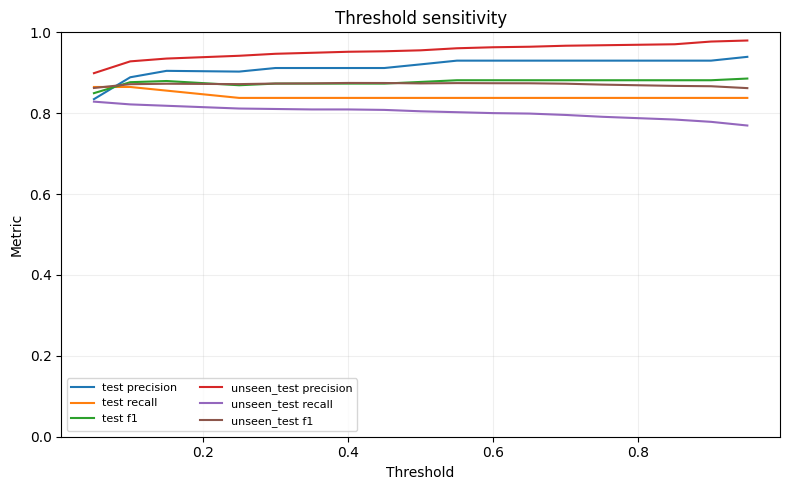

### Best validation threshold

,support,positive_rate,accuracy,precision,recall,f1,TP,FP,TN,FN,fp_rate,fn_rate,roc_auc,pr_auc,brier_score,threshold
0,8465.0,0.0465,0.9896,0.9781,0.7944,0.8768,313.0,7.0,8064.0,81.0,0.0009,0.2056,NaN,NaN,NaN,0.8


### Default vs validation-tuned threshold

,split,setting,threshold,precision,recall,f1
0,test,default_threshold,0.5,0.9208,0.8378,0.8774
1,test,val_tuned_threshold,0.8,0.9300,0.8378,0.8815
2,unseen_test,default_threshold,0.5,0.9555,0.8048,0.8737
3,unseen_test,val_tuned_threshold,0.8,0.9693,0.7877,0.8691


In [11]:
effective_score_kind = next((meta.get("score_kind") for meta in load_metadata.values() if meta.get("has_score")), None)
effective_score_kind = None if effective_score_kind == "unknown" else effective_score_kind
threshold_grid = np.array(THRESHOLD_GRID)
threshold_sweeps = {}
for split_name in ["test", "unseen_test"]:
    if split_name in frames:
        sweep = pea.threshold_sweep(frames[split_name], threshold_grid, score_kind=effective_score_kind)
        if not sweep.empty:
            sweep["split"] = split_name
            threshold_sweeps[split_name] = sweep

if threshold_sweeps:
    threshold_sweep_df = pd.concat(threshold_sweeps.values(), ignore_index=True)
    display(threshold_sweep_df.head().round(4))
    pea.save_dataframe(threshold_sweep_df, OUTPUT_DIR / "threshold_sweep.csv")
    fig = pea.plot_threshold_curves(threshold_sweeps)
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "threshold_sensitivity.png")
    plt.close(fig)
else:
    threshold_sweep_df = pd.DataFrame()
    print("Skipping threshold sweep: no score/probability/logit column available.")

threshold_note = None
if "val" in frames and "score" in frames["val"].columns:
    best_threshold = pea.best_threshold_from_validation(frames["val"], threshold_grid, score_kind=effective_score_kind)
    display(Markdown("### Best validation threshold"))
    display(pd.DataFrame([best_threshold]).round(4))
    comparison_rows = []
    for split_name in ["test", "unseen_test"]:
        if split_name not in frames:
            continue
        base_metrics = pea.compute_binary_metrics(frames[split_name])
        tuned = frames[split_name].copy()
        decision_values = tuned["score_raw"] if effective_score_kind == "logit" and "score_raw" in tuned.columns else tuned["score"]
        tuned["y_pred"] = (decision_values >= best_threshold["threshold"]).astype(int)
        tuned_metrics = pea.compute_binary_metrics(tuned)
        comparison_rows.append({
            "split": split_name,
            "setting": "default_threshold",
            "threshold": THRESHOLD,
            "precision": base_metrics["precision"],
            "recall": base_metrics["recall"],
            "f1": base_metrics["f1"],
        })
        comparison_rows.append({
            "split": split_name,
            "setting": "val_tuned_threshold",
            "threshold": best_threshold["threshold"],
            "precision": tuned_metrics["precision"],
            "recall": tuned_metrics["recall"],
            "f1": tuned_metrics["f1"],
        })
    threshold_comparison = pd.DataFrame(comparison_rows)
    display(Markdown("### Default vs validation-tuned threshold"))
    display(threshold_comparison.round(4))
    pea.save_dataframe(threshold_comparison, OUTPUT_DIR / "threshold_comparison.csv")
    threshold_note = (
        f"Validation-based threshold tuning selected {best_threshold['threshold']:.2f}. "
        "Compare the tuned threshold against the default setting before changing production evaluation defaults."
    )
else:
    display(Markdown("Diagnostic only: validation scores unavailable, so threshold curves should not be used to pick the final threshold."))

## Confidence / Score Analysis

This section checks whether false negatives cluster near the threshold and whether unseen positives receive systematically lower scores than seen positives. If that pattern appears, threshold tuning may improve recall without retraining.

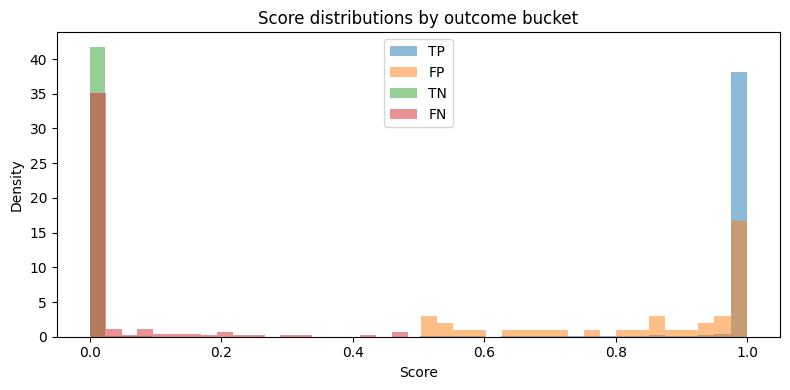

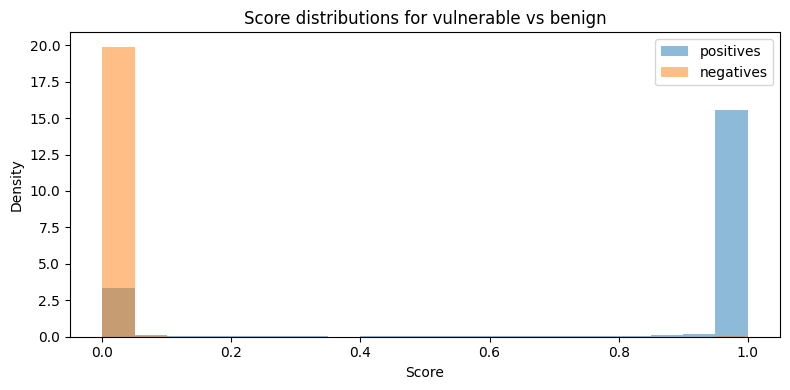

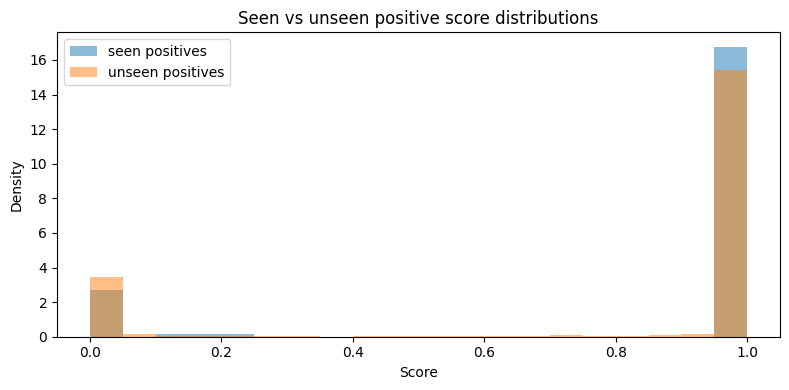

### Reliability table

,prob_bin,support,mean_pred,empirical_rate
0,"(-0.001, 0.1]",18550,0.0003,0.0093
1,"(0.1, 0.2]",19,0.1426,0.4211
2,"(0.2, 0.3]",13,0.2448,0.3846
3,"(0.3, 0.4]",5,0.3467,0.2
4,"(0.4, 0.5]",8,0.4577,0.5
5,"(0.5, 0.6]",11,0.5413,0.3636
6,"(0.6, 0.7]",7,0.6665,0.5714
7,"(0.7, 0.8]",9,0.7443,0.7778
8,"(0.8, 0.9]",14,0.8558,0.5714
9,"(0.9, 1.0]",802,0.9980,0.9713


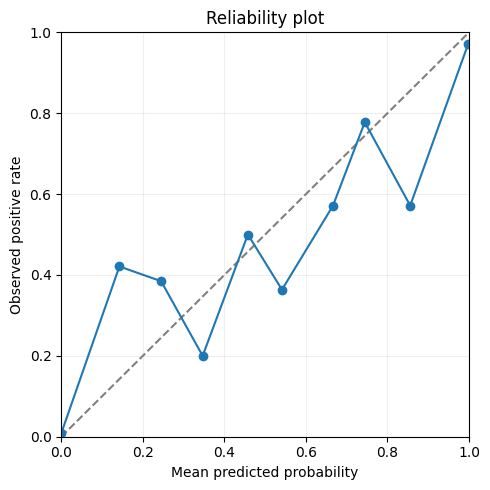

In [12]:
if "score" not in eval_df.columns:
    print("Skipping score distribution analysis: no score/probability/logit column available.")
else:
    scored_eval = eval_df.dropna(subset=["score"]).copy()
    tp = scored_eval[(scored_eval["y_true"] == 1) & (scored_eval["y_pred"] == 1)]
    fp = scored_eval[(scored_eval["y_true"] == 0) & (scored_eval["y_pred"] == 1)]
    tn = scored_eval[(scored_eval["y_true"] == 0) & (scored_eval["y_pred"] == 0)]
    fn = scored_eval[(scored_eval["y_true"] == 1) & (scored_eval["y_pred"] == 0)]

    fig = pea.plot_score_histogram({
        "TP": tp["score"],
        "FP": fp["score"],
        "TN": tn["score"],
        "FN": fn["score"],
    }, "Score distributions by outcome bucket")
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "score_distribution_outcomes.png")
    plt.close(fig)

    fig = pea.plot_score_histogram({
        "positives": scored_eval.loc[scored_eval["y_true"] == 1, "score"],
        "negatives": scored_eval.loc[scored_eval["y_true"] == 0, "score"],
    }, "Score distributions for vulnerable vs benign")
    display(fig)
    pea.save_figure(fig, OUTPUT_DIR / "score_distribution_labels.png")
    plt.close(fig)

    if "is_unseen_cwe" in scored_eval.columns:
        fig = pea.plot_score_histogram({
            "seen positives": scored_eval.loc[(scored_eval["y_true"] == 1) & (scored_eval["is_unseen_cwe"] == 0), "score"],
            "unseen positives": scored_eval.loc[(scored_eval["y_true"] == 1) & (scored_eval["is_unseen_cwe"] == 1), "score"],
        }, "Seen vs unseen positive score distributions")
        display(fig)
        pea.save_figure(fig, OUTPUT_DIR / "score_distribution_seen_vs_unseen_positives.png")
        plt.close(fig)

    reliability = pea.reliability_table(scored_eval)
    if not reliability.empty:
        display(Markdown("### Reliability table"))
        display(reliability.round(4))
        pea.save_dataframe(reliability, OUTPUT_DIR / "reliability_table.csv")
        fig = pea.plot_reliability(reliability)
        display(fig)
        pea.save_figure(fig, OUTPUT_DIR / "reliability_plot.png")
        plt.close(fig)

## Bootstrap Stability

Point estimates are not enough for repeatable comparisons. This section adds bootstrap confidence intervals for `f1`, `precision`, and `recall` on `test` and `unseen_test`.

In [13]:
bootstrap_df = pea.bootstrap_summary(frames, n_bootstrap=N_BOOTSTRAP)
if bootstrap_df.empty:
    print("Skipping bootstrap summary: test/unseen_test predictions not both available.")
else:
    display(bootstrap_df.round(4))
    pea.save_dataframe(bootstrap_df, OUTPUT_DIR / "bootstrap_summary.csv")

delta_rows = []
if {"test", "unseen_test"}.issubset(aggregate_metrics.index):
    for metric_name in ["f1", "precision", "recall"]:
        delta_rows.append({
            "metric": metric_name,
            "test": aggregate_metrics.loc["test", metric_name],
            "unseen_test": aggregate_metrics.loc["unseen_test", metric_name],
            "delta_unseen_minus_test": aggregate_metrics.loc["unseen_test", metric_name] - aggregate_metrics.loc["test", metric_name],
        })
delta_df = pd.DataFrame(delta_rows)
display(Markdown("### Test vs unseen delta"))
display(delta_df.round(4))
pea.save_dataframe(delta_df, OUTPUT_DIR / "test_vs_unseen_delta.csv")

,metric,mean,lower,upper,n_bootstrap,split
0,f1,0.8770,0.8256,0.9231,1000,test
1,precision,0.9211,0.8632,0.9720,1000,test
2,recall,0.8379,0.7685,0.9065,1000,test
3,f1,0.8739,0.8573,0.8904,1000,unseen_test
4,precision,0.9559,0.9417,0.9699,1000,unseen_test
5,recall,0.8050,0.7785,0.8310,1000,unseen_test


### Test vs unseen delta

,metric,test,unseen_test,delta_unseen_minus_test
0,f1,0.8774,0.8737,-0.0037
1,precision,0.9208,0.9555,0.0347
2,recall,0.8378,0.8048,-0.0331


## Comparison Mode

Optional mode for future runs. Point `COMPARISON_SUMMARY_PATHS` to previously exported `aggregate_metrics.csv` files from this notebook to compare runs consistently.

In [14]:
COMPARISON_SUMMARY_PATHS = []

comparison_rows = []
for summary_path in COMPARISON_SUMMARY_PATHS:
    summary_path = Path(summary_path)
    if not summary_path.exists():
        print(f"Missing comparison summary: {summary_path}")
        continue
    summary_df = pd.read_csv(summary_path)
    run_label = summary_path.parent.name
    for split_name in ["test", "unseen_test"]:
        split_df = summary_df[summary_df["split"] == split_name]
        if split_df.empty:
            continue
        row = split_df.iloc[0].to_dict()
        row["run"] = run_label
        comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
if comparison_df.empty:
    print("No comparison summaries configured.")
else:
    display(comparison_df[["run", "split", "precision", "recall", "f1", "support"]].sort_values(["split", "f1"], ascending=[True, False]).round(4))
    pea.save_dataframe(comparison_df, OUTPUT_DIR / "run_comparison.csv")

No comparison summaries configured.


## Final Summary

This is the copy-paste section for reports. It should be concise, stable across runs, and explicit about generalization, conservatism, weak areas, and threshold tuning.

In [15]:
red_flags = pea.red_flag_summary(
    aggregate_metrics,
    per_cwe_df=per_cwe if 'per_cwe' in globals() else None,
    per_project_df=per_project if 'per_project' in globals() else None,
    length_tables=length_tables,
)
report_summary = pea.make_report_summary(
    aggregate_metrics,
    per_cwe_df=per_cwe if 'per_cwe' in globals() else None,
    per_project_df=per_project if 'per_project' in globals() else None,
    threshold_note=threshold_note,
)
display(Markdown("### Report Summary"))
display(Markdown(report_summary))
summary_path = OUTPUT_DIR / "report_summary.md"
summary_path.write_text(report_summary)

if red_flags:
    display(Markdown("### Red Flags"))
    for flag in red_flags:
        display(Markdown(f"- {flag}"))
else:
    display(Markdown("### Red Flags\n- None triggered by the default heuristics."))

display(Markdown("### Saved outputs"))
saved_files = sorted(str(path.relative_to(OUTPUT_DIR)) for path in OUTPUT_DIR.glob("*"))
display(pd.DataFrame({"file": saved_files}))

### Report Summary

- Test: accuracy=0.994, precision=0.921, recall=0.838, f1=0.877.
- Unseen test: accuracy=0.986, precision=0.956, recall=0.805, f1=0.874.
- Unseen F1 change vs test is -0.004 (small gap). Unseen precision change is +0.035; unseen recall change is -0.033. The unseen pattern looks conservative: recall drops more than precision.
- Weak CWEs by F1: CWE-254, CWE-290, CWE-79.
- Weak projects by F1: lynx-snapshots, yubico-pam, mongoose-os.
- Validation-based threshold tuning selected 0.80. Compare the tuned threshold against the default setting before changing production evaluation defaults.

### Red Flags

- 9 supported unseen CWE(s) have near-zero recall.

- token_length bucket 0-64 has high FN rate (0.72).

- char_length bucket >4096 has high FN rate (0.56).

### Saved outputs

,file
0,aggregate_metrics.csv
1,bootstrap_summary.csv
2,char_length_stratified_metrics.csv
3,line_count_stratified_metrics.csv
4,per_cwe_metrics.csv
5,per_cwe_support_vs_f1.png
6,per_cwe_support_vs_recall.png
7,per_project_metrics.csv
8,per_project_support_vs_f1.png
9,reliability_plot.png
